# Notebook 02: Single-Target Candidate Search

**Purpose:** Run the full pipeline on one user-specified target and generate a candidate-vetting report.

> Run notebook 01 first to confirm the pipeline recovers known signals.

In [1]:
import sys, logging
sys.path.insert(0, '../src')
logging.basicConfig(level=logging.INFO, format='%(levelname)s %(name)s: %(message)s')

import matplotlib
matplotlib.use('inline')
%matplotlib inline

from tesshunter import download, preprocessing, bls_search, plotting, vetting, catalog_crossmatch, reporting
from tesshunter.config import PLOTS_DIR, CANDIDATES_DIR


C:\Users\samzu\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


## Configuration — edit these cells

In [ ]:
# ── Mission & target ──────────────────────────────────────────────────────────
# TESS example:    TARGET = 278892590          MISSION = "TESS"    SECTOR = None
# K2 example:      TARGET = "EPIC 200164267"   MISSION = "K2"      CAMPAIGN = 12
# Kepler example:  TARGET = "KIC 9414417"      MISSION = "Kepler"  QUARTER = 5
TARGET   = 278892590            # int TIC, "EPIC NNN", "KIC NNN", or a name
MISSION  = "TESS"               # "TESS", "K2", or "Kepler"
SECTOR   = None                 # TESS: specific sector(s), or None = all
CAMPAIGN = None                 # K2:   specific campaign(s), or None = all
QUARTER  = None                 # Kepler: specific quarter(s), or None = all
AUTHOR   = "SPOC"               # pipeline author: "SPOC", "K2SFF", "EVEREST", None

# Human-readable label used in plot titles and the report filename
TARGET_LABEL = "TIC 278892590"

# TIC ID for TESS catalog cross-match.
# Set to None when using K2/Kepler — cell 13 tries to resolve it automatically.
TIC_ID   = 278892590

# ── BLS search ────────────────────────────────────────────────────────────────
PERIOD_MIN = 1.0
PERIOD_MAX = 13.0   # 2+ transits in a typical 27-day TESS sector

DURATION_MIN = 0.01
DURATION_MAX = 0.12

# Number of BLS peaks returned per pass.
TOP_N = 20

# Broad BLS frequency-grid resolution.  None = auto (baseline × frequency_factor).
# 5000 gives finer period resolution and better separation of closely-spaced signals.
N_PERIODS = 5000

# ── Preprocessing ─────────────────────────────────────────────────────────────
DO_FLATTEN     = True
FLATTEN_WINDOW = 0.5
SIGMA          = 4.0
BIN_MINUTES    = 10.0

# ── Detection thresholds ──────────────────────────────────────────────────────
MAX_PLANETS            = 5
SNR_MIN                = 5.0   # gate 1: minimum raw BLS rank-1 SNR to keep searching
SNR_MIN_RESOLVED       = 5.0   # gate 2: minimum resolved SNR to accept a candidate
MIN_EVENT_COMPLETENESS = 0.5   # gate 3: fraction of transit windows with a real dip
MIN_COMPOSITE_SCORE    = 3.0   # gate 4: SNR × ev_comp × (1 − overlap)

# Periods (days) to suppress before peak extraction.
# Leave empty [] for TESS.  Add 1.0 for K2 (spacecraft roll systematic).
ARTIFACT_PERIODS = []

# ── Known-period diagnostic ───────────────────────────────────────────────────
# After each accepted planet is masked, the loop checks whether these periods
# remain visible in the residual.  Set to {} to disable (default for blind search).
KNOWN_PERIODS = {}

## Step 1: Download

In [3]:
import warnings
warnings.filterwarnings("ignore", message=".*zero-centered.*")

lcc = download.search_and_download_lc(
    target   = TARGET,
    mission  = MISSION,
    sector   = SECTOR,
    campaign = CAMPAIGN,
    quarter  = QUARTER,
    author   = AUTHOR,
)
if lcc is None:
    raise RuntimeError(f"No data found for {TARGET!r} ({MISSION})")

lc_raw  = download.stitch_collection(lcc)
sectors = download.observing_units_available(lcc, MISSION)

_ulabels = {"TESS": "Sector", "K2": "Campaign", "KEPLER": "Quarter"}
_ulabel  = _ulabels.get(MISSION.upper(), "Unit")
print(f"Mission: {MISSION}  |  {_ulabel}(s): {sectors}  |  Cadences: {len(lc_raw)}")

INFO tesshunter.download: Searching MAST for EPIC 200164267  mission=K2  exptime=long
WARNING tesshunter.download: No light curves found for EPIC 200164267 (K2)
INFO tesshunter.download: Retrying without author='K2SFF'...
INFO tesshunter.download: Found 1 product(s) — attempting batch download...
7% (242/3599) of the cadences will be ignored due to the quality mask (quality_bitmask=1130799).
INFO lightkurve.utils: 7% (242/3599) of the cadences will be ignored due to the quality mask (quality_bitmask=1130799).
INFO tesshunter.download: Batch download succeeded: 1 light curve(s)
INFO tesshunter.download: Stitched 1 sectors → 3357 cadences spanning 78.9 days (median flux ~1.0)


Mission: K2  |  Campaign(s): [12]  |  Cadences: 3357


## Step 2: Preprocess

In [4]:
lc_clean, prep_record = preprocessing.preprocess(
    lc_raw, sigma=SIGMA, do_flatten=DO_FLATTEN, flatten_window=FLATTEN_WINDOW
)
print("Preprocessing notes:")
for n in prep_record.notes:
    print(f"  {n}")


INFO tesshunter.preprocessing: Preprocessing complete: 3357 → 3269 cadences


Preprocessing notes:
  Removed 88 cadences (2.6%)


## Step 3: BLS Search

In [5]:
lc_binned = preprocessing.bin_lightcurve(lc_clean, bin_minutes=BIN_MINUTES)
print(f"Binned: {len(lc_clean)} cadences -> {len(lc_binned)} cadences (binned)")

# Broad BLS search — no assumptions about what period to expect
bls_model, bls_result, candidates = bls_search.run_bls(
    lc_binned,
    period_min=PERIOD_MIN,
    period_max=PERIOD_MAX,
    duration_min=DURATION_MIN,
    duration_max=DURATION_MAX,
    top_n=TOP_N,
)

# score = SNR x completeness (penalises periods whose transits fall in sector gaps)
print(candidates[["peak_rank","period_days","depth_ppt","duration_days","snr","score"]].to_string(index=False))


INFO tesshunter.preprocessing: Binned 3269 → 3269 cadences (10-min bins)
INFO tesshunter.bls_search: BLS search (numpy engine): periods 18.20–19.30 d, 500 freq points, 10 durations, 3269 cadences


Binned: 3269 cadences -> 3269 cadences (binned)


INFO tesshunter.bls_search: BLS complete. Top candidate: 18.8815 d  depth 8.03 ppt  SNR 8.8


 peak_rank  period_days  depth_ppt  duration_days      snr    score
         1    18.881488   8.027487       0.105589 8.835136 8.835136


## Step 3b-3c: Iterative Planet Detection

Each pass runs a broad BLS on the residual light curve, resolves period aliases (half-period check, alternating-event consistency, event completeness, and physical window overlap against prior planets), then masks the found planet and repeats.

The loop stops when no signal above SNR_MIN remains, or MAX_PLANETS have been found.

In [ ]:
import pandas as pd

# ── Iterative planet detection ────────────────────────────────────────────────
# All thresholds (MAX_PLANETS, SNR_MIN, SNR_MIN_RESOLVED, MIN_EVENT_COMPLETENESS,
# MIN_COMPOSITE_SCORE, ARTIFACT_PERIODS, KNOWN_PERIODS) come from the config cell.
#
# Each pass:
#   1. Bin the working LC (lc_clean initially; masks accumulate each pass).
#   2. Run a broad BLS on the residual — TOP_N candidates.
#   3. GATE 1 — stop if even rank-1 SNR < SNR_MIN (pure-noise pass).
#   4. Iterate over ALL TOP_N candidates:
#      a. Skip known artifact periods (ARTIFACT_PERIODS).
#      b. Resolve aliases (half-period dip, alternating events,
#         event completeness, physical window overlap vs. prior planets).
#      c. GATES 2-4 — reject if resolved SNR / ev_comp / composite < thresholds.
#      d. Collect survivors in resolved_pool.
#   5. Stop if resolved_pool is empty (no real signal remains).
#      Otherwise pick the best candidate by composite score.
#   6. Accept the planet, mask it from the UNBINNED working LC (width_factor=7).
#   7. Post-mask SNR check + optional known-period diagnostic.
#
# Key: step 4 tries every top-N BLS peak, not just rank 1.  After masking, the
# strongest residual is often a junk/artifact signal while real planets sit at
# rank 5, 12, 20.  This is especially true for K2 where 1-day roll artifacts
# can dominate the residual even after a real transit has been masked.

# Backward-compatible fallbacks for new config variables
try:
    _artifact_periods = ARTIFACT_PERIODS
except NameError:
    _artifact_periods = [1.0]

try:
    _known_periods = KNOWN_PERIODS
except NameError:
    _known_periods = {}

try:
    _n_periods = N_PERIODS      # override BLS frequency-grid size (None = auto)
except NameError:
    _n_periods = None

_disp = ["harmonic_label", "trial_period", "period_days",
         "depth_ppt", "snr", "event_completeness",
         "alternating_flag", "overlap", "composite_score"]

found_planets = []
working_lc    = lc_clean

for _idx in range(MAX_PLANETS):
    planet_num = _idx + 1
    print(f"\n{'='*62}")
    print(f"  Detection pass {planet_num}")
    print(f"{'='*62}")

    working_binned = preprocessing.bin_lightcurve(working_lc, bin_minutes=BIN_MINUTES)

    # ── Broad BLS ─────────────────────────────────────────────────────────
    # suppress_periods zeros out artifact-period power before peak extraction,
    # preventing artifacts from (a) consuming candidate slots and (b) triggering
    # harmonic masking that would erase real signals at nearby periods.
    _, _, raw_cands = bls_search.run_bls(
        working_binned,
        period_min       = PERIOD_MIN,
        period_max       = PERIOD_MAX,
        duration_min     = DURATION_MIN,
        duration_max     = DURATION_MAX,
        top_n            = TOP_N,
        suppress_periods = _artifact_periods,
        n_periods        = _n_periods,
    )

    if raw_cands.empty:
        print("No BLS candidates returned — stopping.")
        break

    top = raw_cands.iloc[0]
    print(f"Broad BLS top:  {top['period_days']:.4f} d  "
          f"depth {top['depth_ppt']:.3f} ppt  SNR {top['snr']:.1f}  "
          f"({len(raw_cands)} candidates)")

    # Gate 1: fast exit when even rank-1 is clearly below threshold
    if top["snr"] < SNR_MIN:
        print(f"  STOP (gate 1): top SNR {top['snr']:.1f} < {SNR_MIN}")
        break

    # ── Try every top-N candidate; collect survivors ───────────────────────
    existing_df   = pd.DataFrame(found_planets) if found_planets else None
    resolved_pool: list[tuple] = []  # (resolved_series, trial_table_df)

    print(f"\nResolving {len(raw_cands)} BLS candidate(s)...")
    for _, raw_cand in raw_cands.iterrows():
        p = raw_cand["period_days"]

        # Skip known instrument / sampling artifact periods
        if any(abs(p / bad - 1.0) < 0.02 for bad in _artifact_periods):
            print(f"  [{p:.4f} d]  artifact period -- skip")
            continue

        resolved, trial_table = bls_search.resolve_aliases_for_candidate(
            working_binned,
            raw_cand,
            existing_candidates = existing_df,
            period_min   = PERIOD_MIN,
            period_max   = PERIOD_MAX,
            duration_min = DURATION_MIN,
            duration_max = DURATION_MAX,
        )

        ev_comp    = resolved.get("event_completeness", float("nan"))
        comp_score = resolved.get("composite_score", resolved["snr"])
        r_p        = resolved["period_days"]

        # Also skip if alias resolution chose an artifact period
        # (e.g. raw=2.010 d -> resolver picks P/2=1.005 d)
        if any(abs(r_p / bad - 1.0) < 0.02 for bad in _artifact_periods):
            print(f"  [{p:.4f} d -> {r_p:.4f} d]  resolved to artifact -- skip")
            continue

        if resolved["snr"] < SNR_MIN_RESOLVED:
            print(f"  [{p:.4f} d -> {r_p:.4f} d]  "
                  f"SNR {resolved['snr']:.1f} < {SNR_MIN_RESOLVED}  (gate 2)")
            continue
        if not (ev_comp >= MIN_EVENT_COMPLETENESS):   # NaN-safe
            print(f"  [{p:.4f} d -> {r_p:.4f} d]  "
                  f"ev_comp {ev_comp:.2f} < {MIN_EVENT_COMPLETENESS}  (gate 3)")
            continue
        if comp_score < MIN_COMPOSITE_SCORE:
            print(f"  [{p:.4f} d -> {r_p:.4f} d]  "
                  f"composite {comp_score:.2f} < {MIN_COMPOSITE_SCORE}  (gate 4)")
            continue

        print(f"  [{p:.4f} d -> {r_p:.4f} d]  "
              f"SNR {resolved['snr']:.1f}  ev_comp {ev_comp:.2f}  "
              f"composite {comp_score:.2f}  PASS")
        resolved_pool.append((resolved, trial_table))

    if not resolved_pool:
        print("\nNo candidate survived quality gates -- stopping.")
        break

    # ── Pick best survivor by composite score ─────────────────────────────
    resolved, best_trial = max(
        resolved_pool,
        key=lambda rt: rt[0].get("composite_score", rt[0]["snr"]),
    )
    ev_comp    = resolved.get("event_completeness", float("nan"))
    comp_score = resolved.get("composite_score", resolved["snr"])

    print(f"\nAlias trial table (best candidate):")
    if not best_trial.empty:
        print(best_trial[_disp].to_string(index=False))

    print(f"\nAccepted planet {planet_num}: [{resolved['harmonic_label']}]  "
          f"P = {resolved['period_days']:.6f} d  "
          f"depth {resolved['depth_ppt']:.3f} ppt  "
          f"SNR {resolved['snr']:.1f}  "
          f"ev_comp {ev_comp:.2f}  "
          f"composite {comp_score:.2f}")

    found_planets.append({
        "planet_num":         planet_num,
        "period_days":        resolved["period_days"],
        "epoch_btjd":         resolved["epoch_btjd"],
        "duration_days":      resolved["duration_days"],
        "depth_ppt":          resolved["depth_ppt"],
        "power":              resolved.get("power", 0.0),
        "snr":                resolved["snr"],
        "event_completeness": ev_comp,
        "harmonic_label":     resolved.get("harmonic_label", "P"),
    })

    # ── Mask and verify ───────────────────────────────────────────────────
    working_lc = preprocessing.mask_transits(
        working_lc,
        period       = resolved["period_days"],
        epoch        = resolved["epoch_btjd"],
        duration     = resolved["duration_days"],
        width_factor = 7.0,
    )
    check_binned = preprocessing.bin_lightcurve(working_lc, bin_minutes=BIN_MINUTES)
    _, _, chk = bls_search.run_bls(
        check_binned,
        period_min   = resolved["period_days"] * 0.98,
        period_max   = resolved["period_days"] * 1.02,
        duration_min = DURATION_MIN,
        duration_max = DURATION_MAX,
        top_n = 3,
    )
    if chk.empty:
        print(f"Post-mask check ({resolved['period_days']:.4f} d): signal gone.")
    else:
        psnr = chk.iloc[0]["snr"]
        flag = "  WARNING: still elevated -- check width_factor" if psnr > 5 else "  OK"
        print(f"Post-mask check ({resolved['period_days']:.4f} d): SNR = {psnr:.1f}{flag}")

    # ── Known-period diagnostic ────────────────────────────────────────────
    if _known_periods:
        print(f"\nKnown-period diagnostic "
              f"(residual after planet {planet_num} masked):")
        for _name, _p in _known_periods.items():
            _, _, _local = bls_search.run_bls(
                check_binned,
                period_min   = _p * 0.98,
                period_max   = _p * 1.02,
                duration_min = DURATION_MIN,
                duration_max = DURATION_MAX,
                top_n = 3,
            )
            if _local.empty:
                print(f"  {_name} ({_p:.4f} d): no signal")
            else:
                _b = _local.iloc[0]
                print(f"  {_name} ({_p:.4f} d): "
                      f"P={_b['period_days']:.4f} d  "
                      f"depth={_b['depth_ppt']:.3f} ppt  "
                      f"SNR={_b['snr']:.1f}")

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\n{'='*62}")
print(f"Detection complete -- {len(found_planets)} candidate(s) found")
print(f"{'='*62}")
planets_df = pd.DataFrame(found_planets)
if not planets_df.empty:
    _sumcols = ["planet_num", "period_days", "depth_ppt",
                "snr", "event_completeness", "harmonic_label"]
    print(planets_df[_sumcols].to_string(index=False))

# Downstream aliases
best    = planets_df.iloc[0] if not planets_df.empty else None
planet2 = planets_df.iloc[1] if len(planets_df) > 1 else None

## Step 4: Catalog Cross-match

In [7]:
import re

# ── Resolve TIC ID for catalog cross-match ─────────────────────────────────
# For TESS:     set TIC_ID = <int> in the config cell above.
# For K2/Kepler: leave TIC_ID = None; this cell resolves it from the target name.
if TIC_ID is not None:
    _resolved_tic = TIC_ID
else:
    _m = re.match(r"TIC\s*(\d+)", str(TARGET), re.IGNORECASE)
    if _m:
        _resolved_tic = int(_m.group(1))
    else:
        print(f"Resolving TIC ID for {TARGET!r} via MAST (may take a few seconds)...")
        _resolved_tic = download.get_tic_id_from_name(str(TARGET))
        if _resolved_tic:
            print(f"  Resolved TIC ID: {_resolved_tic}")
        else:
            print("  Could not resolve TIC ID — cross-match will be skipped.")

# Update TIC_ID so downstream cells can reference it consistently
TIC_ID = _resolved_tic  # may be None if resolution failed

if TIC_ID is not None:
    xmatch = catalog_crossmatch.crossmatch(TIC_ID)
else:
    xmatch = {
        "tic_metadata":      None,
        "toi_entries":       None,
        "confirmed_planets": None,
        "is_known_toi":      False,
        "is_confirmed_planet": False,
        "summary_str": (
            f"No TIC ID could be resolved for {TARGET!r} — "
            "catalog cross-match skipped."
        ),
    }

print("Cross-match summary:")
print(xmatch["summary_str"])
print(f"Is known TOI       : {xmatch['is_known_toi']}")
print(f"Is confirmed planet: {xmatch['is_confirmed_planet']}")

tic_meta = xmatch.get("tic_metadata") or {}
stellar_radius = tic_meta.get("stellar_radius_rsun")
if stellar_radius:
    print(f"Stellar radius from TIC: {stellar_radius:.3f} R_Sun")
else:
    print("Stellar radius not available -- planet radius estimate will be skipped.")

Resolving TIC ID for 'EPIC 200164267' via MAST (may take a few seconds)...
  Could not resolve TIC ID — cross-match will be skipped.
Cross-match summary:
No TIC ID could be resolved for 'EPIC 200164267' — catalog cross-match skipped.
Is known TOI       : False
Is confirmed planet: False
Stellar radius not available -- planet radius estimate will be skipped.


## Step 5: Vetting

In [8]:
import pandas as pd

try:
    _planets = planets_df
except NameError:
    _planets = pd.DataFrame()

# ── Branch on whether the detection loop accepted any candidates ───────────────
# Do NOT fall back to the raw BLS rank-1 candidate when the loop found nothing.
# That would vet a noise peak as if it were a real planet.

if _planets.empty:
    print("Detection loop found no accepted candidates.")
    print("Skipping vetting — there is nothing to vet.")
    best = None
    vet  = None

else:
    best = _planets.iloc[0]

    # Vet Planet 1 in full.  For multi-planet systems, per-planet vetting can
    # be added by looping over _planets rows and calling run_vetting() for each.
    vet = vetting.run_vetting(
        lc_clean,
        period_days         = best["period_days"],
        epoch_btjd          = best["epoch_btjd"],
        duration_days       = best["duration_days"],
        depth_ppt           = best["depth_ppt"],
        n_sectors           = len(sectors),
        stellar_radius_rsun = stellar_radius,
        is_known_toi        = xmatch["is_known_toi"],
    )

    print(f"Planet 1 vetting  P = {best['period_days']:.6f} d")
    print(f"VERDICT           : {vet.verdict}")
    print("\nVetting notes:")
    for n in vet.notes:
        print(f"  {n}")

    _sumcols = [c for c in
                ["planet_num", "period_days", "depth_ppt",
                 "snr", "event_completeness", "harmonic_label"]
                if c in _planets.columns]
    if len(_planets) > 1:
        print("\nAll detected candidates:")
        print(_planets[_sumcols].to_string(index=False))


INFO tesshunter.vetting: Vetting verdict: needs review (flags=0)


Planet 1 vetting  P = 18.612420 d
VERDICT           : needs review

Vetting notes:
  Depth 10.4 ppt is within planet regime.
  Duration/period = 0.004 is acceptable.
  Odd depth 0.71 ppt, even depth 8.89 ppt, delta = 2.1σ.
  Secondary eclipse depth at phase 0.5: -0.18 ppt (3σ threshold: 23.03 ppt).
  Signal observed in only 1 sector — cannot confirm consistency.
  TODO: Centroid analysis not implemented. Requires target pixel files (TPFs).
  TODO: Nearby-star contamination check not implemented. Requires Gaia DR3 cone search.

All detected candidates:
 planet_num  period_days  depth_ppt      snr  event_completeness harmonic_label
          1    18.612420  10.390187 6.031310                 1.0              P
          2    18.287684  10.129742 7.898409                 1.0              P
          3    19.239526   9.276348 6.373125                 0.5              P


## Step 6: Diagnostic Plots

In [9]:
# Periodogram, raw, and cleaned plots don't depend on any detected candidate.
# Folded and zoom plots require 'best' (Planet 1); skip them when nothing was found.
plot_paths = plotting.all_diagnostic_plots(
    lc_raw, lc_clean, bls_result, candidates, TARGET_LABEL
)

if best is not None:
    plot_paths["folded"] = plotting.plot_folded_lightcurve(
        lc_clean,
        best["period_days"], best["epoch_btjd"], best["duration_days"],
        TARGET_LABEL,
    )
    plot_paths["zoom"] = plotting.plot_transit_zoom(
        lc_clean,
        best["epoch_btjd"], best["duration_days"], best["period_days"],
        TARGET_LABEL,
    )
else:
    print("No accepted candidates — skipping folded and zoom plots.")

print("Plots saved:")
for k, p in plot_paths.items():
    print(f"  {k}: {p}")


Plots saved:
  raw: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\plots\TRAPPIST-1 _ K2 C12 — f_g_h search\raw_lightcurve.png
  cleaned: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\plots\TRAPPIST-1 _ K2 C12 — f_g_h search\cleaned_lightcurve.png
  periodogram: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\plots\TRAPPIST-1 _ K2 C12 — f_g_h search\bls_periodogram.png
  folded: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\plots\TRAPPIST-1 _ K2 C12 — f_g_h search\folded_P18.6124d.png
  zoom: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\plots\TRAPPIST-1 _ K2 C12 — f_g_h search\transit_zoom.png


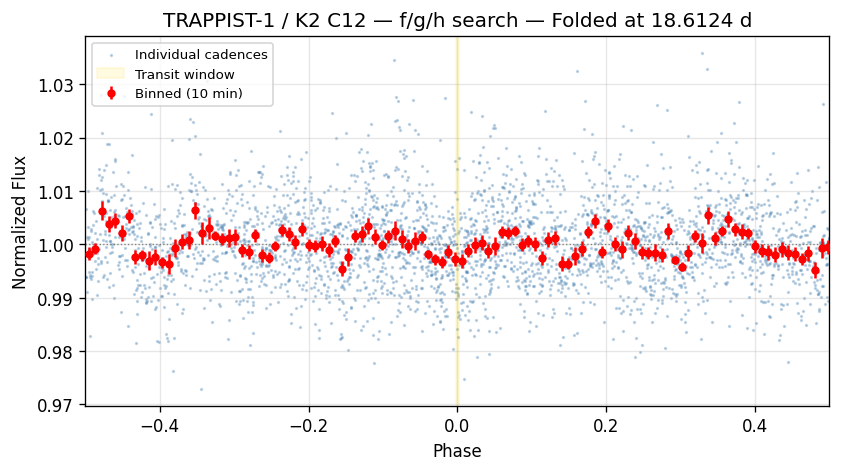

In [10]:
from IPython.display import Image
if "folded" in plot_paths:
    display(Image(str(plot_paths["folded"])))


## Step 7: Generate Report

In [11]:
import pandas as pd

try:
    import tabulate as _tab
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "tabulate", "-q"], check=True)

try:
    _planets = planets_df
except NameError:
    _planets = pd.DataFrame()

# ── Guard: nothing to report when no candidates were accepted ─────────────────
if best is None or vet is None:
    print("No accepted candidates — skipping report and CSV entry.")

else:
    # TIC_ID may be None (K2/Kepler without resolved TIC); fall back to 0
    _report_tic = TIC_ID or 0

    # Generate the markdown report.
    # candidates = raw first-pass BLS peaks (for the periodogram-peaks reference).
    # _planets   = alias-resolved multi-planet list (drives Section 2 table).
    report_path = reporting.generate_report(
        target_id          = TARGET_LABEL,
        tic_id             = _report_tic,
        sectors            = sectors,
        prep_record        = prep_record,
        candidates_df      = candidates,
        vetting            = vet,
        crossmatch_summary = xmatch["summary_str"],
        plot_paths         = plot_paths,
        planets_df         = _planets,
        mission            = MISSION,
    )
    print(f"Report written: {report_path}")

    # Append one CSV row per accepted planet.
    for _, p in _planets.iterrows():
        pnum = int(p.get("planet_num", 1))
        reporting.append_to_candidate_summary(
            tic_id             = _report_tic,
            target_id          = f"{TARGET_LABEL} P{pnum}",
            sectors            = sectors,
            period_days        = p["period_days"],
            depth_ppt          = p["depth_ppt"],
            duration_hours     = p["duration_days"] * 24,
            bls_power          = float(p.get("power", 0.0)),
            snr                = p["snr"],
            verdict            = vet.verdict if pnum == 1 else "candidate",
            crossmatch_summary = xmatch["summary_str"],
            summary_csv        = CANDIDATES_DIR / "candidate_summary.csv",
        )

INFO tesshunter.reporting: Report written: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\reports\TRAPPIST-1 _ K2 C12 — f_g_h search\candidate_report_TRAPPIST-1___K2_C12_—_f_g_h_search.md
INFO tesshunter.reporting: Updated candidate summary: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\candidates\candidate_summary.csv
INFO tesshunter.reporting: Updated candidate summary: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\candidates\candidate_summary.csv
INFO tesshunter.reporting: Updated candidate summary: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\candidates\candidate_summary.csv


Report written: C:\Users\samzu\Downloads\tess-exoplanet-candidate-hunter\notebooks\..\outputs\reports\TRAPPIST-1 _ K2 C12 — f_g_h search\candidate_report_TRAPPIST-1___K2_C12_—_f_g_h_search.md
